# 08 P1 P2 redes y comunidades

Este notebook **solo lee artefactos publicados**. No transforma los datos, no ejecuta Spark y no entrena modelos. Resume P1, centralidades, Louvain, el nulo de Puno y BigCLAM para la discusión de las Partes IV y V.

Las etiquetas se mantienen como *participantes reportados*. Ningún patrón de red, comunidad o membresía solapada prueba colusión, fraude, competencia efectiva ni define un mercado real.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / 'artifacts').exists():
    ROOT = ROOT.parent

def require_success(path: Path) -> Path:
    if not (path / '_SUCCESS').is_file():
        raise FileNotFoundError(f'No hay un artefacto publicado completo: {path}')
    return path

def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding='utf-8'))

print(f'Raíz del proyecto: {ROOT}')

Raíz del proyecto: C:\Users\HP\Desktop\2026-02\DataMining\Proyecto2


## P1 Concentración y participación reportada

La pregunta es asociativa, no causal. La lectura principal usa el resultado centrado por estratos para procesos competitivos comparables; el bootstrap remuestrea compradores completos.

In [2]:
p1_dir = require_success(ROOT / 'artifacts/p1/analysis')
p1 = pd.read_csv(p1_dir / 'association_results.csv')
primary = p1.loc[
    (p1.scenario == 'all_awards')
    & (p1.participation_measure == 'reported_participants_median')
    & (p1.adjustment == 'stratum_centered'),
    ['minimum_processes', 'correlation', 'ci_low', 'ci_high', 'units', 'strata'],
].sort_values('minimum_processes')
display(primary.style.format({'correlation': '{:.3f}', 'ci_low': '{:.3f}', 'ci_high': '{:.3f}'}))
display(Markdown('**Lectura:** los intervalos de la asociación ajustada incluyen cero; no se sostiene una asociación persistente en este diseño.'))

,minimum_processes,correlation,ci_low,ci_high,units,strata
1,10,-0.050,-0.136,0.078,535,85
5,20,0.079,-0.144,0.259,140,30


**Lectura:** los intervalos de la asociación ajustada incluyen cero; no se sostiene una asociación persistente en este diseño.

## P2 Centralidades y partición Louvain

HITS usa el bipartito comprador--proveedor adjudicado. PageRank y Louvain usan la proyección de co-participación filtrada a procesos con hasta 30 participantes recurrentes. Las figuras siguientes presentan sensibilidad ya calculada; no recalculan centralidades ni comunidades.

,nodos PageRank,aristas PageRank,damping,iteraciones HITS
0,25379,1698528,"[0.75, 0.85, 0.95]",211


,resolution,seed,modularity,community_count,largest_community_nodes,largest_community_share
0,0.5,7,0.561677,498,6510,0.256511
1,0.5,42,0.584039,399,5455,0.214941
2,0.5,99,0.586397,404,4958,0.195358
3,1.0,7,0.630626,37,5154,0.203081
4,1.0,42,0.633156,35,5268,0.207573
5,1.0,99,0.628172,39,4568,0.179991
6,1.5,7,0.626376,43,4020,0.158399
7,1.5,42,0.629337,49,4083,0.160881
8,1.5,99,0.622559,46,3944,0.155404


,resolution,left_seed,right_seed,ari
0,0.5,7,42,0.639783
1,0.5,7,99,0.670545
2,0.5,42,99,0.771418
3,1.0,7,42,0.768200
4,1.0,7,99,0.851295
5,1.0,42,99,0.706116
6,1.5,7,42,0.858056
7,1.5,7,99,0.868838
8,1.5,42,99,0.839899


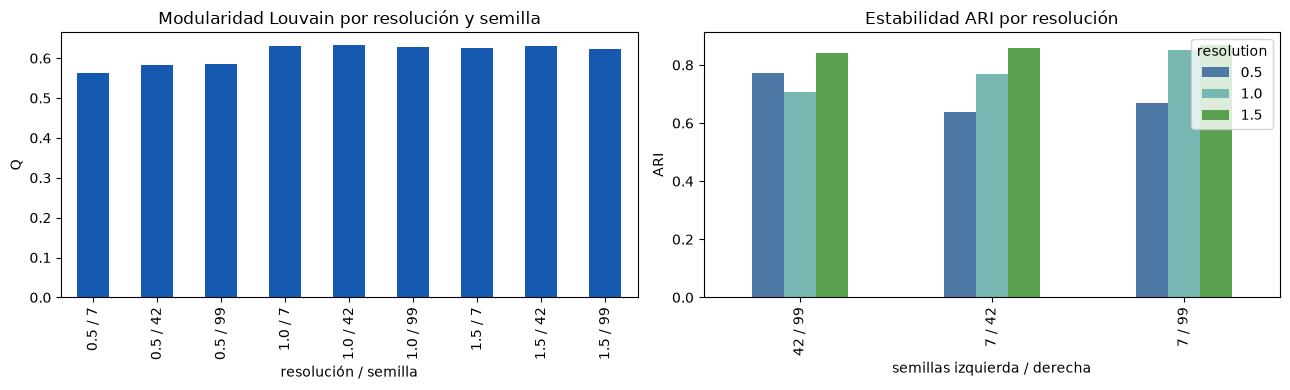

In [3]:
links_dir = require_success(ROOT / 'artifacts/p2/links')
communities_dir = require_success(ROOT / 'artifacts/p2/communities')
links = read_json(links_dir / 'metadata.json')
runs = pd.read_csv(communities_dir / 'runs.csv')
stability = pd.read_csv(communities_dir / 'stability.csv')
display(pd.DataFrame([{
    'nodos PageRank': links['pagerank']['nodes'],
    'aristas PageRank': links['pagerank']['undirected_edges'],
    'damping': links['pagerank']['damping'],
    'iteraciones HITS': links['hits']['iterations'],
}]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
runs.assign(config=runs.resolution.astype(str) + ' / ' + runs.seed.astype(str)).plot(
    x='config', y='modularity', kind='bar', ax=axes[0], legend=False, color='#1559b0'
)
axes[0].set(title='Modularidad Louvain por resolución y semilla', xlabel='resolución / semilla', ylabel='Q')
stability.assign(pair=stability.left_seed.astype(str) + ' / ' + stability.right_seed.astype(str)).pivot(
    index='pair', columns='resolution', values='ari'
).plot(kind='bar', ax=axes[1], color=['#4e79a7', '#76b7b2', '#59a14f'])
axes[1].set(title='Estabilidad ARI por resolución', xlabel='semillas izquierda / derecha', ylabel='ARI')
plt.tight_layout()
display(runs.sort_values(['resolution', 'seed']))
display(stability.sort_values(['resolution', 'left_seed', 'right_seed']))

## Puno Nulo y comunidades solapadas

Puno fue fijado antes como subgrafo ejecutable para el nulo Curveball. BigCLAM se aplica al mismo alcance de participantes recurrentes y corte de tamaño de proceso. Su AUC y AP son diagnósticos de reconstrucción sobre el mismo grafo, no una validación prospectiva.

,valor
Puno Q observada,0.612
Puno Q nulo media,0.087
nodos BigCLAM,1908.000
aristas BigCLAM,84962.000
miembros múltiples,0.337
AUC de reconstrucción,0.921
AP de reconstrucción,0.903


,community,members,dominant_louvain_community,overlap_members,dominant_louvain_members,jaccard_with_dominant_louvain
0,0,307,13,134,246,0.320
1,1,359,4,156,273,0.328
2,2,319,13,205,246,0.569
3,3,570,10,180,216,0.297
4,4,373,9,194,267,0.435
5,5,311,10,103,216,0.243
6,6,216,0,85,86,0.392
7,7,331,1,98,98,0.296


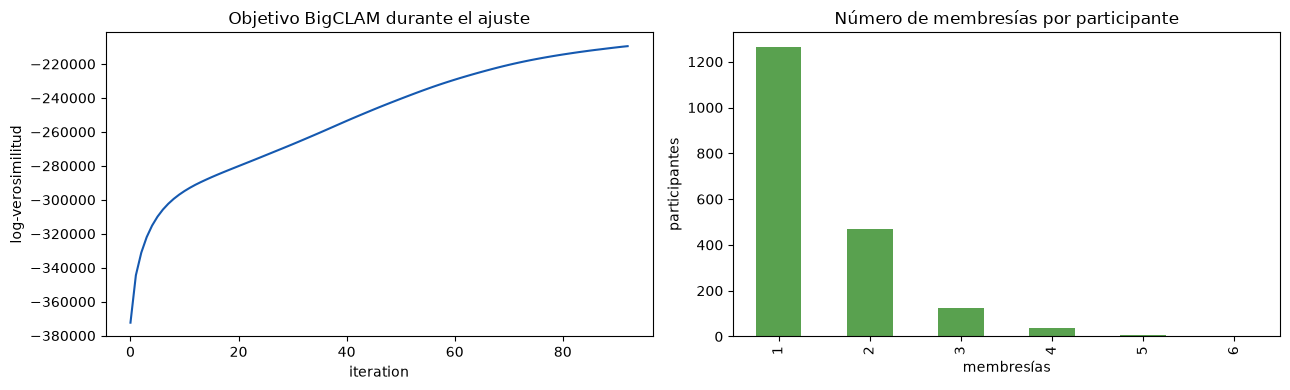

In [4]:
null_dir = require_success(ROOT / 'artifacts/p2/null_puno')
overlap_dir = require_success(ROOT / 'artifacts/p2/overlap_puno')
null_summary = read_json(null_dir / 'summary.json')
overlap = read_json(overlap_dir / 'metadata.json')
memberships = pd.read_parquet(overlap_dir / 'memberships.parquet')
comparison = pd.read_csv(overlap_dir / 'overlap_louvain_comparison.csv')
optimization = pd.read_csv(overlap_dir / 'optimization_diagnostics.csv')

display(pd.DataFrame([{
    'Puno Q observada': null_summary['observed_modularity'],
    'Puno Q nulo media': null_summary['null_mean'],
    'nodos BigCLAM': overlap['coverage']['nodes_in_projection'],
    'aristas BigCLAM': overlap['coverage']['edges_in_projection'],
    'miembros múltiples': overlap['coverage']['share_nodes_in_multiple_communities'],
    'AUC de reconstrucción': overlap['diagnostics']['sampled_reconstruction_auc'],
    'AP de reconstrucción': overlap['diagnostics']['sampled_reconstruction_average_precision'],
}]).T.rename(columns={0: 'valor'}).style.format('{:.3f}'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
optimization.plot(x='iteration', y='objective', ax=axes[0], legend=False, color='#1559b0')
axes[0].set(title='Objetivo BigCLAM durante el ajuste', ylabel='log-verosimilitud')
memberships.groupby('participant_id').size().value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color='#59a14f'
)
axes[1].set(title='Número de membresías por participante', xlabel='membresías', ylabel='participantes')
plt.tight_layout()
display(comparison.style.format({'jaccard_with_dominant_louvain': '{:.3f}'}))

## Conclusión de Partes IV y V

Louvain resume una partición estable de la red k<=30; BigCLAM añade pertenencias múltiples en Puno y no reemplaza esa partición. El contraste con el nulo describe una estructura de co-participación más marcada que el nulo especificado para Puno. Ninguno de estos resultados identifica carteles, mercados jurídicos ni conducta irregular.

In [5]:
assert memberships.participant_id.nunique() == overlap['coverage']['nodes_with_membership']
assert len(memberships) == overlap['coverage']['memberships']
assert optimization.objective.is_monotonic_increasing
print('Lectura consistente: los artefactos publicados coinciden con sus metadatos.')

Lectura consistente: los artefactos publicados coinciden con sus metadatos.
